**Цель работы:** исследование методов численного многомерного интегрирования с применением нейронных сетей, а также сравнение результатов с аналитическими решениями.    

**Актуальность:** многомерные интегралы встречаются в различных задачах науки и техники (например, в статистической физике, квантовой механике и машинном обучении). Решение таких интегралов аналитически может быть крайне сложным, что требует применения численных методов.

**Постановка задачи**  
Математическая модель: рассматривается задача вычисления интеграла функции $ f(x) = 0.5 \sum x_i^2 $ в пространстве размерности $n$ с произвольными пределами интегрирования.  
Цель: получение точного аналитического решения с помощью символьных методов и сравнение его с численным решением, полученным при помощи метода Левенберга-Марквардта, использующего нейронные сети.

$$ f(x_1...x_n) = \frac{1}{2} (x_1^2 +...+ x_n^2), x_1... x_n \in [-1, 1] $$


$$
I_{\text{true}} = \int_{-1}^{1} \cdots \int_{-1}^{1} \frac{1}{2} \left( x_{0}^{2} + x_{1}^{2} + \cdots + x_{n}^{2} \right) \, dx_{0} \, dx_{1} \, \cdots \, dx_{n}
$$

[Понятие о многомерных интегралах](https://alexandr4784.narod.ru/budakfom/budakfom_02_05.pdf)


-----------------------------------------------------
Для аналитического выбора количества точек N в однородной сетке для заданного количества измерений n можно использовать формулу: $M = N^n$

N = 71 - количество точек в каждом измерении, а не общее количеством точек в сетке.   
M - общее количество точек в сетке, n - количество измерений, это поможет  выбрать такое N, чтобы количество точек было близко к заданному числу M.
$$N = \left\lceil \sqrt[n]{M} \right\rceil$$
$$71 = \left\lceil \sqrt[2]{5041} \right\rceil$$
В этой формуле $\lceil \cdot \rceil$ обозначает округление вверх до ближайшего целого числа.



-----------------------------------------------------------
Код выводит графики проекций $n$-мерной функции на плоскости переменных $x_i \times x_j$ для всех комбинаций $i$ и $j$.

На графиках проекций изображены точки, представляющие собой значения переменных $x_i$ и $x_j$ на осях $x$ и $y$ соответственно. Цвет каждой точки определяется значением функции $f$ в соответствующей точке. Таким образом, цвет точек показывает, как значение функции изменяется в пространстве переменных $x_i$ и $x_j$.Код обеспечивает визуализацию, которая помогает понять взаимосвязь между переменными и значением функции в многомерном пространстве.

[Многомерные графики в Python — от трёхмерных и до шестимерных](https://habr.com/ru/articles/456282/)   
[Как построить многомерную функцию в Python?](https://translated.turbopages.org/proxy_u/en-ru.ru.b749f79a-661eb579-9176cd4b-74722d776562/https/stackoverflow.com/questions/30336138/how-to-plot-a-multivariate-function-in-python?__ya_mt_enable_static_translations=1)   
[Множественная линейная регрессия и визуализация в Python](https://aegis4048.github.io/mutiple_linear_regression_and_visualization_in_python)

𝑁 – это общее количество точек в обучающей выборке, которые используются для аппроксимации подынтегральной функции. Увеличение 𝑁 (например, с 10^3 до 10^5) позволяет повысить точность аппроксимации, так как сеть обучается на большем объеме данных. Однако при больших значениях
𝑁 возрастает время, необходимое для обучения нейронной сети, особенно в задачах с высокими требованиями к вычислительным ресурсам.

𝑛 – это размерность области интегрирования, то есть количество измерений пространства, в котором выполняется интегрирование. При увеличении размерности
𝑛 задача усложняется, так как пространство, которое нужно охватить обучающей выборкой, становится больше. Соответственно, для более высоких
𝑛 требуется больше точек
𝑁 для сохранения точности, так как аппроксимация становится сложнее.

Зависимость 𝑛 и
𝑁 состоит в том, что с увеличением размерности
𝑛 необходимо большее
𝑁, чтобы обеспечить достаточную плотность точек для точной аппроксимации подынтегральной функции и вычисления интеграла.

У канадцев в их коде N и n задаются константами как 71 и 2 соответственно.

-----------------------------------------------------------------
**Сетка** представляет собой набор точек внутри области, в которой мы хотим посчитать интеграл. Эти точки выбираются двумя способами:

- Равномерно: часть точек просто распределяется равномерно по всей области.
- С помощью метода Метрополиса-Гастингса: этот метод выбирает больше точек в тех местах, где функция, от которой считается интеграл, имеет большие значения (например, резкие пики).
Сетка нужна, чтобы у нейронной сети были примеры (точки и значения функции в них) для обучения. Сеть «учится» понимать, как функция ведёт себя в разных точках.

Когда нейросеть обучена, мы больше не используем сетку напрямую. Вместо этого сеть уже знает, как выглядит функция, и может вычислить интеграл в этой области или даже в новой, похожей области, без дополнительного обучения.








---------------------------------------------------------
**Аналитический метод** – это подход, при котором результат выражается в виде точной математической формулы, используя свойства функции и известных операций (например, интегралов, производных). Аналитические решения часто подразумевают точное выражение ответа, и если он получен, то дальнейшие вычисления не нужны. Пример: интеграл
$\int x^2 \, dx = \frac{x^3}{3} + C$


**Символьный метод** – это процесс, который позволяет преобразовывать, манипулировать и решать выражения в символической форме, сохраняя их в виде математических символов, а не чисел. Символьные вычисления включают аналитические методы, так как работают с точными выражениями, но также могут включать упрощение выражений, разложение их в ряды и преобразования, не всегда приводящие к конечному ответу. Пример: символьное дифференцирование выражения
$f(x) = x^2 + \sin(x)$ даст результат
$2x + \cos(x)$


**Численный метод** – это метод, в котором результат приближённый, и находится путём вычислений с числами. Обычно численные методы применяются, когда аналитический (символьный) результат невозможно получить, и тогда интегралы или дифференциальные уравнения решаются численно, с заданной точностью. Пример: численное вычисление интеграла
$\int_{0}^{1} x^2 \, dx$
 может дать
0.333... с нужной точностью.

*Связь между аналитическим и символьным методом:*  
- Аналитический метод может быть частью символьного метода, если он приводит к точному выражению.
- Однако символьный метод более общий и может включать преобразования и упрощения выражений, которые не обязательно приводят к полному аналитическому решению.    

То есть   
$\text{Аналитический метод} \not= \text{Символьный метод}$


In [ ]:
# !pip install tensorflow==2.15.1

In [ ]:
pip install tf-levenberg-marquardt

In [ ]:
pip install keras

In [ ]:
import tensorflow as tf
print(tf.__version__)

2.21.0


Если использовать равномерное распределение точек по сетке, то будет возникать ошибка по следующим причинам:   
- Количество измерений и точек: при использовании функции np.meshgrid для создания точек в
𝑛-мерном пространстве, количество генерируемых точек может быстро возрастать. Например, если
𝑛=6 и
𝑁=1000, NumPy попытается создать массив с размерностью 1000^6
 , что является огромным числом (1 триллион точек). Это превышает ограничения по памяти и приводит к ошибке.   
- Функция np.linspace: Каждый вызов np.linspace создает массив из
𝑁 точек, что означает, что в итоге мы получаем массив размером
𝑁^𝑛
  после выполнения np.meshgrid.

При равномерном распределении для каждой переменной $ x_i $ создается равномерно распределенный массив из $ N $ точек от $ a[i] $ до $ b[i] $. Затем с помощью `np.meshgrid` создается сетка всех возможных комбинаций этих точек. В итоге мы получаем массив $ X $ размером $ N^n $, что может быстро привести к огромному числу точек в многомерном пространстве, из-за чего возникает ошибка (недостаток памяти)


При случайном распределении генерируются $N $ точек в $n $-мерном пространстве. Для каждой точки значение выбирается из равномерного распределения между $a[i] $ и $b[i] $ для каждой переменной $x_i $. Это значительно уменьшает размер генерируемого массива до $N $ точек, что делает этот метод более подходящим для высокоразмерных задач, так как он не сталкивается с проблемой экспоненциального роста числа точек.


N - это общее количество точек, а не количество точек в каждом измерении.

Комментируем np.random.shuffle(X), если хотим изобразить все точки разными цветами (но будут проблемы ниже, поскольку batch_size маленький). Если все точки одним цветом, то оставляем np.random.shuffle(X).

Многомерная кубатурная формула Гаусса-Лежандра для численного интегрирования:

$$
\int_{a_1}^{b_1} \cdots \int_{a_n}^{b_n} f(x_1, \dots, x_n)\,dx_1 \cdots dx_n
\approx \sum_{k_1=1}^{m} \cdots \sum_{k_n=1}^{m}
\left[ f\left(x_{k_1}, \dots, x_{k_n}\right)
\prod_{i=1}^{n} w_{k_i} \right]
$$


- $ m $ — число узлов для каждого измерения.
- $ x_{k_i} $ — узлы Гаусса-Лежандра, преобразованные на отрезок $[a_i, b_i]$ по формуле:
$$
x_{k_i} = \frac{b_i - a_i}{2} \cdot t_{k_i} + \frac{b_i + a_i}{2}
$$
где $ t_{k_i} $ — узлы на отрезке \([-1, 1]\).

- $ w_{k_i} $ — веса Гаусса-Лежандра, масштабированные по формуле:
$$
w_{k_i}^{(trans)} = \frac{b_i - a_i}{2} \cdot w_{k_i}
$$




1. Метод Монте-Карло
$$
I \approx V \cdot \frac{1}{N} \sum_{i=1}^{N} f(x_i)
$$
где $ V = \prod_{i=1}^{n} (b_i - a_i) $ — объем области интегрирования.

---

2. Квази-Монте-Карло (Sobol)
$$
I \approx V \cdot \frac{1}{N} \sum_{i=1}^{N} f(x_i)
$$
где точки \( x_i \) выбираются из последовательности Sobol.

---

3. Метод Гаусса-Лежандра
$$
I \approx \sum_{i_1=1}^{m} \sum_{i_2=1}^{m} \dots \sum_{i_n=1}^{m} f(x_{i_1}, x_{i_2}, \dots, x_{i_n}) \prod_{j=1}^{n} w_{i_j}
$$
где $ x_{i_j} $ — трансформированные узлы, $ w_{i_j} $ — соответствующие веса.

---

4. Метод средних прямоугольников
$$
I \approx \sum_{i_1=1}^{N} \sum_{i_2=1}^{N} \dots \sum_{i_n=1}^{N} f(x_{i_1}, x_{i_2}, \dots, x_{i_n}) \cdot \prod_{j=1}^{n} \Delta x_j
$$
где $ x_{i_j} $ — середины подотрезков, $ \Delta x_j = \frac{b_j - a_j}{N} $.

---

5. Метод Симпсона
$$
I \approx \frac{h_1 h_2 \dots h_n}{3^n} \sum f(x_{i_1}, x_{i_2}, \dots, x_{i_n}) \cdot C(i_1) \cdot C(i_2) \dots C(i_n)
$$
где $ h_j = \frac{b_j - a_j}{N-1} $, а коэффициенты Симпсона:
$$
C(i) =
\begin{cases}
1, & \text{если } i \text{ — крайний} \\
4, & \text{если } i \text{ нечетный} \\
2, & \text{если } i \text{ четный}
\end{cases}
$$

---

6. Метод трапеций
$$
I \approx \sum f(x_{i_1}, x_{i_2}, \dots, x_{i_n}) \cdot w(x_{i_1}) \cdot w(x_{i_2}) \dots w(x_{i_n}) \cdot \prod_{j=1}^{n} h_j
$$
где $ h_j = \frac{b_j - a_j}{N-1} $, а веса:
$$
w(x_i) =
\begin{cases}
0.5, & \text{если } x_i \text{ — крайний} \\
1, & \text{иначе}
\end{cases}
$$

---

7. Адаптивный метод квадратур
$$
I = \int_{a_1}^{b_1} \int_{a_2}^{b_2} \dots \int_{a_n}^{b_n} f(x_1, x_2, \dots, x_n) \,dx_1 dx_2 \dots dx_n
$$
где пределы делятся на подотрезки, пока разница между последовательными оценками не станет меньше заданного допуска $ \varepsilon $.


**Программа для ЭВМ «Комбинированное сэмплирование с параметром ρ для интегрирования тестовых функций»**

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import quad
from scipy.integrate import nquad
from mpl_toolkits.mplot3d import Axes3D
from scipy.special import roots_legendre
import numba
import time
from scipy.integrate import dblquad


SEED = 13
np.random.seed(SEED)

n = 2
N = 1000

# Доля граничных точек
border_ratio = 0.12
N_border = int(N * border_ratio)

# ro от 0 до 1
roo = 0.4

# Вычисляем количество точек
N_mg = int(roo * (N - N_border))
N_uniform = (N - N_border) - N_mg

ro = N_mg / (N_mg + N_uniform)
# print(ro)

def generate_data(n, N, a, b, N_uniform, N_mg, N_border):

    # Равномерные точки
    X_uniform = np.random.uniform(a, b, size=(N_uniform, n))

    # Функция Метрополиса-Гастингса
    def metropolis_hastings(n, N, a, b):
        X_mg = np.zeros((N, n))
        x_current = np.random.uniform(a, b, size=n)

        for i in range(N):
            x_proposed = x_current + np.random.normal(scale=0.2, size=n)
            x_proposed = np.clip(x_proposed, a, b)
            alpha = min(1, np.exp(-np.sum(x_proposed**2)) / np.exp(-np.sum(x_current**2)))
            # alpha = min(1, (np.sum(x_proposed**2) / np.sum(x_current**2)) if np.sum(x_current**2) != 0 else 1)

            if np.random.rand() < alpha:
                x_current = x_proposed
            X_mg[i] = x_current
        return X_mg

    X_mg = metropolis_hastings(n, N_mg, a, b)

    # Добавляем угловые точки
    corners = np.array(np.meshgrid(*[[a[i], b[i]] for i in range(n)])).T.reshape(-1, n)
    X_border = list(corners)

    # Корректируем количество оставшихся граничных точек
    remaining_border = N_border - len(corners)
    if remaining_border > 0:
        num_per_edge = max(1, remaining_border // (2 * n))  # Гарантируем хотя бы 1 точку на грань
        for dim in range(n):
            for bound in [a[dim], b[dim]]:
                for _ in range(num_per_edge):
                    point = np.random.uniform(a, b, size=n)
                    point[dim] = bound  # Фиксируем одну координату на границе
                    X_border.append(point)

    X_border = np.array(X_border)

    # Объединяем все точки
    X = np.vstack([X_uniform, X_mg, X_border])
    np.random.shuffle(X)
    return X

def input_integration_limits(n):
    a = [0, 0]
    b = [1, 1]
    # a = []
    # b = []
    # for i in range(n):
    #     a_i = float(input(f"Введите нижний предел интегрирования для x{i}: "))
    #     b_i = float(input(f"Введите верхний предел интегрирования для x{i}: "))
    #     a.append(a_i)
    #     b.append(b_i)
    return np.array(a), np.array(b)


# Ввод пределов интегрирования
a, b = input_integration_limits(n)

#---------Многомерная функция Гаусса----------
def gaussian(X, center=None, sigma=None):
    X = np.atleast_2d(X)  # X имеет форму (N, d)
    if center is None:
        center = np.array([(b[i] + a[i]) / 2 for i in range(n)])
    if sigma is None:
        sigma = np.ones(n)*0.1
    exponent = -0.5 * np.sum(((X - center) / sigma)**2, axis=1)
    return np.exp(exponent) / np.prod(sigma * np.sqrt(2 * np.pi))

# Аналитическое вычисление интеграла функции Гаусса
from scipy.integrate import quad

def compute_analytical_integral_gaussian(n, a_range, b_range, center=None, sigma=None):
    if center is None:
        center = np.array([(b_range[i] + a_range[i]) / 2 for i in range(n)])
    if sigma is None:
        sigma = np.ones(n)*0.1

    def integrand(x, i):
        return np.exp(-0.5 * ((x - center[i]) / sigma[i])**2) / (sigma[i] * np.sqrt(2 * np.pi))

    integral_value = 1.0
    for i in range(n):
        result, _ = quad(integrand, a_range[i], b_range[i], args=(i,))
        integral_value *= result
    return integral_value

# Вычисление аналитического интеграла для Гаусса
# I_true = compute_analytical_integral_gaussian(n, a, b)
# print("Аналитическое значение интеграла (Гаусс):", I_true)

#----------синус суммы квадратов------------
def ellipse(X):
    X = np.atleast_2d(X)  # X имеет форму (N, d)
    return np.sin(np.sum(X**2, axis=1))

def compute_analytical_integral_ellipse(n, a_range, b_range):
    X = sp.symbols(f'x0:{n}')
    f_ellipse = sp.sin(sum(X[i]**2 for i in range(n)))
    I_ellipse = f_ellipse
    for i in range(n):
        I_ellipse = sp.integrate(I_ellipse, (X[i], a_range[i], b_range[i]))
    return I_ellipse.evalf()

# Вычисление аналитического интеграла функции
# I_true = compute_analytical_integral_ellipse(n, a, b)
# print("Аналитическое значение интеграла (синус суммы квадратов):", I_true)

#---------квадратичная------------
def f_paraboloid(X):
    if X.ndim == 1: # одномерный массив (скаляр)
        return 0.5 * np.sum(X**2)
    return 0.5 * np.sum(X**2, axis=1)

X_sum = sp.symbols(' '.join([f'x{i}' for i in range(n)]))
f_sym = 0.5 * sum(X_sum[i]**2 for i in range(n))

# Вычисление истинного интеграла
limits = [(X_sum[i], a[i], b[i]) for i in range(n)]

I_true = sp.integrate(f_sym, *limits).evalf()
print("Аналитическое значение интеграла (параболоид):", I_true)

# ---------corner peak--------------
def copeak(X, u=None, a=None):
    if X.ndim == 1:
        d = X.shape[0]
    else:
        d = X.shape[1]

    if u is None:
        u = np.full(d, 0.5)
        a = np.full(d, 5)
    elif a is None:
        a = np.full(d, 5)
    total_sum = np.dot(X, a)

    # Вычисляем значение функции
    y = (1 + total_sum) ** (-d - 1)
    return y

u = np.ones(n) * 0.5
a_corner = np.ones(n) * 5.0

def compute_analytical_integral_copeak(n, a_vals, a_range, b_range):
    X = sp.symbols(f'x0:{n}')
    a_sym = sp.symbols(f'a0:{n}')

    #  функция copeak
    func = (1 + sum(a_sym[i] * X[i] for i in range(n))) ** (-n - 1)

    limits = [(X[i], a_range[i], b_range[i]) for i in range(n)]

    #  аналитический интеграл
    I_sym = sp.integrate(func, *limits)

    #  численные значения для a
    subs_dict = {a_sym[i]: a_vals[i] for i in range(n)}
    I_numeric = I_sym.subs(subs_dict).evalf()
    return I_numeric

a_vals_copeak = [5.0] * n  # Параметр a из copeak

# I_true = compute_analytical_integral_copeak(n, a_vals_copeak, a, b)
# print("Аналитическое значение интеграла (corner peak):", I_true)
# ----------------------------------------------------------------------

# Генерация данных и вычисление значений функции
X = generate_data(n, N, a, b, N_uniform, N_mg, N_border)

y = f_paraboloid(X)
# y = copeak(X, u, a_corner)
# y = gaussian(X)
# y = ellipse(X)

# print("\nОбщее количество точек N:", N)
print("Относительная объемная доля ro:", ro)
print(f"N_uniform = {N_uniform}, N_mg = {N_mg}, N_border = {N_border}")

Аналитическое значение интеграла (параболоид): 0.333333333333333
Относительная объемная доля ro: 0.4
N_uniform = 528, N_mg = 352, N_border = 120


In [5]:
import gc
gc.collect()

694

## **Программа для ЭВМ «Сравнение методов численного интегрирования на тестовых функциях»**

In [6]:
import itertools
import time
import numpy as np

In [7]:
#----------Метод Монте-Карло--------------
def integrate_with_monte_carlo(f, a, b, n, N):
    start = time.time()
    # Генерация N случайных точек в n-мерном пространстве
    samples = np.random.uniform(a, b, (N, n))
    # Вычисление объема интегрируемой области
    volume = np.prod(np.array(b) - np.array(a))
    integral = volume * np.mean(f(samples))
    end = time.time()
    return integral, end - start

#-----------------------------------------------
# Квази-Монте-Карло с последовательностью Sobol (точки распределены более равномерно)
from scipy.stats import qmc
def integrate_with_quasi_monte_carlo(f, a, b, n, N):
    start = time.time()
    # Создание последовательности Соболя размерности n
    sampler = qmc.Sobol(d=n, scramble=True)
    # Масштабирование точек в заданный интервал
    samples = qmc.scale(sampler.random(N), a, b)
    volume = np.prod(np.array(b) - np.array(a))
    integral = volume * np.mean(f(samples))
    end = time.time()
    return integral, end - start

#--------метод Гаусса-Лежандра------
from scipy.special import roots_legendre

def integrate_with_gauss(f, a, b, n, m, nodes, weights):
    start = time.time()

    # Масштабирование узлов и весов в заданные пределы
    transformed_nodes = [0.5 * (nodes * (b[i] - a[i]) + (b[i] + a[i])) for i in range(n)]
    transformed_weights = [0.5 * (b[i] - a[i]) * weights for i in range(n)]

    integral = 0.0

    # вложенные циклы для вычисления интеграла
    for indices in np.ndindex(*[m] * n):
        # Вычисляем точку и вес для текущей комбинации узлов
        point = np.array([transformed_nodes[i][indices[i]] for i in range(n)])
        weight = np.prod([transformed_weights[i][indices[i]] for i in range(n)])

        integral += f(point) * weight

    end = time.time()
    return float(integral.item()), end - start

# Генерация узлов и весов Гаусса-Лежандра
nodes, weights = roots_legendre(5)  # m=5 узлов


def integrate_with_gauss(f, a, b, n, m, nodes, weights):
    start = time.time()

    # Масштабируем узлы и веса в заданные пределы
    transformed_nodes = [0.5 * (nodes * (b[i] - a[i]) + (b[i] + a[i])) for i in range(n)]
    transformed_weights = [0.5 * (b[i] - a[i]) * weights for i in range(n)]

    # Формируем сетку из всех комбинаций узлов
    grids = np.meshgrid(*transformed_nodes, indexing='ij')
    points = np.column_stack([g.flatten() for g in grids])

    # Комбинируем веса для всех измерений
    weight_grids = np.meshgrid(*transformed_weights, indexing='ij')
    combined_weights = np.prod([w.flatten() for w in weight_grids], axis=0)

    # Вычисляем интеграл
    integral = np.sum(f(points) * combined_weights)
    end = time.time()
    return integral, end - start

# Генерация узлов и весов Гаусса-Лежандра
nodes, weights = roots_legendre(50)  # m=5 узлов

# #--------------Метод Латинского гиперкуба-------------
# Более равномерное покрытие пространства, чем у стандартного метода Монте-Карло
# делит каждое измерение области интегрирования на N равных интервалов и случайным образом выбирает по одной точке из каждого интервала
def latin_hypercube_sampling(f, a, b, n, N):
    start = time.time()

    # Генерация точек
    samples = np.zeros((N, n))
    for i in range(n):
        samples[:, i] = np.random.permutation(N) + np.random.uniform(0, 1, N)
    samples = (samples / N) * (np.array(b) - np.array(a)) + np.array(a)

    # Оценка интеграла
    volume = np.prod(np.array(b) - np.array(a))
    integral = volume * np.mean(f(samples))
    end = time.time()
    return integral, end - start

#--------Метод сэмплирования по Халтону--------------
# метод использует последовательность Халтона для более равномерного покрытия пространства
def halton_sequence(size, dim):
    def halton(index, base):
        result = 0
        f = 1 / base
        i = index
        while i > 0:
            result += f * (i % base)
            i = i // base
            f = f / base
        return result

    primes = [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31]
    samples = np.zeros((size, dim))
    for i in range(dim):
        base = primes[i]
        samples[:, i] = [halton(j, base) for j in range(1, size + 1)]
    return samples

def integrate_with_halton(f, a, b, n, N):
    start = time.time()

    # Генерация точек по Халтону
    samples = halton_sequence(N, n)
    samples = samples * (np.array(b) - np.array(a)) + np.array(a)

    # Оценка интеграла
    volume = np.prod(np.array(b) - np.array(a))
    integral = volume * np.mean(f(samples))

    end = time.time()
    return integral, end - start

#------------Метод Симпсона----------------
def integrate_with_simpson(f, a, b, n, N):
    start = time.time()
    # Шаги интегрирования
    h = [(b[i] - a[i]) / (N - 1) for i in range(n)]
    integral = 0

    # Генерируем индексы всех точек (без хранения в памяти)
    for indices in itertools.product(range(N), repeat=n):
        point = np.array([a[i] + indices[i] * h[i] for i in range(n)])

        # Вычисляем коэффициенты Симпсона
        coeff = 1
        for i in range(n):
            if indices[i] == 0 or indices[i] == N - 1:
                coeff *= 1
            elif indices[i] % 2 == 1:
                coeff *= 4
            else:
                coeff *= 2

        integral += coeff * f(point)

    # Умножаем на объем элементарных ячеек и нормируем по Симпсону
    integral *= np.prod(h) / (3 ** n)
    end = time.time()
    return  float(integral.item()), end - start

#--------Выбор функции-------------
f = f_paraboloid
# f = gaussian
# f = copeak
# f = ellipse

# Вычисление интегралов
I_gauss, gauss_time = integrate_with_gauss(f, a, b, n, m=5, nodes=nodes, weights=weights)
I_monte_carlo, mc_time = integrate_with_monte_carlo(f, a, b, n, N)
I_integrate_with_quasi_monte_carlo, mc_time = integrate_with_quasi_monte_carlo(f, a, b, n, N)
I_lhs, lhs_time = latin_hypercube_sampling(f, a, b, n, N)
I_halton, halton_time = integrate_with_halton(f, a, b, n, N)
I_simpson, simpson_time = integrate_with_simpson(f, a, b, n, N)


# Вывод результатов
print(f"Аналитическое значение интеграла: {I_true}\n")
print(f"Гаусс-Лежандр: {I_gauss}, Время: {gauss_time:.6f} сек")
print(f"Монте-Карло: {I_monte_carlo}, Время: {mc_time:.6f} сек")
print(f"Квази-Монте-Карло Sobol: {I_integrate_with_quasi_monte_carlo}, Время: {mc_time:.6f} сек")
print(f"Метод Латинского гиперкуба: {I_lhs}, Время: {lhs_time:.6f} сек")
print(f"Метод сэмплирования по Хэлтону: {I_halton}, Время: {halton_time:.6f} сек")
print(f"Метод Симпсона: {I_simpson}, Время: {simpson_time:.6f} сек")



/tmp/ipykernel_2622/2518857652.py:20: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  samples = qmc.scale(sampler.random(N), a, b)


Аналитическое значение интеграла: 0.333333333333333

Гаусс-Лежандр: 0.3333333333333327, Время: 0.000400 сек
Монте-Карло: 0.33822122320263603, Время: 0.024502 сек
Квази-Монте-Карло Sobol: 0.333155627897389, Время: 0.024502 сек
Метод Латинского гиперкуба: 0.33334417011529666, Время: 0.000297 сек
Метод сэмплирования по Хэлтону: 0.33194778437143496, Время: 0.002910 сек
Метод Симпсона: 0.33288888922277926, Время: 11.737783 сек


##**Программа для ЭВМ «Реализация нейросетевого метода (NNI)»**

In [8]:
pip install tf-levenberg-marquardt

In [9]:
from sklearn.preprocessing import MinMaxScaler
# hidden_units

scalers = [MinMaxScaler(feature_range=(a[i], b[i])) for i in range(n)]
X_scaled = np.zeros_like(X)
for i in range(n):
    X_scaled[:, i] = scalers[i].fit_transform(X[:, i].reshape(-1, 1)).flatten()

y_scaled = scalers[0].fit_transform(np.expand_dims(y, axis=1)).flatten()

from sklearn.model_selection import train_test_split
X_train, X_valid, y_train, y_valid = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=SEED)
X_train.shape, X_valid.shape

((800, 2), (200, 2))

In [10]:
import random as python_random
import tensorflow as tf
from keras.layers import Dense, Input
from keras.models import Model
from keras.losses import MeanSquaredError
import tf_levenberg_marquardt as lm
from keras import backend as K

class MeanSquaredErrorWithResiduals(MeanSquaredError):
    def residuals(self, y_true, y_pred):
        return y_true - y_pred

loss_function = MeanSquaredErrorWithResiduals()

def get_net(input_units, hidden_units, seed):
    python_random.seed(seed)
    tf.random.set_seed(seed)
    tf.keras.backend.set_floatx('float64')

    input_tensor = Input(shape=(input_units,))
    x = Dense(hidden_units, activation='sigmoid')(input_tensor)
    output_tensor = Dense(1, activation='linear')(x)
    model = Model(inputs=input_tensor, outputs=output_tensor)

    model_wrapper = lm.model.ModelWrapper(model)
    model_wrapper.compile(
        optimizer=tf.keras.optimizers.SGD(learning_rate=1.0),
        loss=loss_function,
        solve_method='qr',
        jacobian_max_num_rows=100,
        attempts_per_step=10
    )

    return model_wrapper

def get_k(N, n, k1=4.33, k2=16):
    return int(pow(np.log10(N), -k1) * k2 * N / (n+2))

k = get_k(X_train.shape[0], n)
model = get_net(n, k, SEED)

# bs = 0.0512
start_time = time.time()

history = model.fit(
    X_train,
    y_train,
    # batch_size=X_train.shape[0],
    batch_size=512,
    # batch_size=int(bs*X_train.shape[0]),
    epochs=100,
    validation_data=(X_valid, y_valid),
    verbose=1
)

Epoch 1/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0037 - val_loss: 0.0039
Epoch 2/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 465ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0037 - val_loss: 0.0039
Epoch 3/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 321ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0037 - val_loss: 0.0038
Epoch 4/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 367ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0036 - val_loss: 0.0038
Epoch 5/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 276ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0036 - val_loss: 0.0038
Epoch 6/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 623ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0036 - val_loss: 0.0038
Epoch 7/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 397ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0036 - val_loss: 0.0037
Epoch 8/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 294ms/step - attempts: 2.0000 - 

Время обучения нейронки: 1.098750352859497
Память: 1121.67 МБ


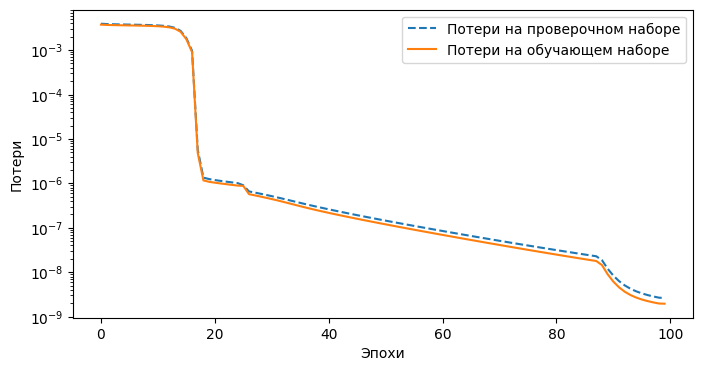

In [11]:
end_time = time.time()

learning_time = (end_time - start_time) / 60
print(f"Время обучения нейронки: {learning_time}")

import psutil
print(f"Память: {psutil.Process().memory_info().rss / 1024 ** 2:.2f} МБ")

plt.figure(figsize=(8, 4))
plt.plot(history.history["val_loss"], label="Потери на проверочном наборе", linestyle="dashed")
plt.plot(history.history["loss"], label="Потери на обучающем наборе")
plt.xlabel("Эпохи")
plt.ylabel("Потери")
plt.yscale("log")
plt.legend()

In [14]:
results = model.evaluate(X_valid, y_valid, batch_size=X_valid.shape[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - loss: 2.6231e-09


In [15]:
from mpmath import polylog

def Li(s, X):
    return np.array([float(polylog(s, x)) for x in X])

def get_xsi(r, d, n):
    degree = int(r / pow(2, n-d))
    return pow(-1, degree)

def get_Xsi(n, FD=False):
    r = 2**n
    Xsi = []
    for r in range(1, r+1):
        row = []
        for d in range(1, n+1):
            row.append(get_xsi(r, d, n))
        xsi = np.prod(row)
        Xsi.append(xsi)
    if FD:
        return -1*np.array(Xsi) # Fermi-Dirac version
    else:
        return np.array(Xsi)

def get_l(r, i, n):
    num = int(r / pow(2, n-i))
    if num % 2 == 0:
        return 0
    else:
        return 1

def get_L(n):
    r = 2**n
    L = []
    for r in range(1, r+1):
        row = []
        for i in range(1, n+1):
            row.append(get_l(r, i, n))
        L.append(row)
    return L

def getNNI(W1, b1, W2, b2, a, b, n):
    # Вычисление размера области интегрирования
    ba_term = np.prod(b - a)
    # Создание массива из нижних и верхних пределов интегрирования
    ab = np.array([a, b])
    X = []
    # Получение матрицы L, определяющей, какие компоненты входных данных использовать в каждой точке сетки
    L = get_L(n)
    for l in L:
        # Инициализация переменной x значением смещения второго слоя нейронной сети
        x = - b1
        # Проход по каждой компоненте входных данных
        for i in range(n):
            # Вычитание взвешенной компоненты входных данных из x
            x -= W1[i] * ab[l[i], i]
        X.append(x)

    # Вычисление весов Xsi для каждой точки сетки
    Xsi = get_Xsi(n, False)
    # Вычисление значений Fi для каждой точки сетки
    Fi = np.array([xsi * Li(n, -np.exp(x, dtype=np.float128)) for xsi, x in zip(Xsi, X)])
    Fi = np.sum(Fi, axis=0)
    I = b2[0] * ba_term + np.sum(W2.flatten() * (ba_term + Fi / np.prod(W1, axis=0)))
    return I

import time
start_time = time.time()

W1, b1, W2, b2= model.get_weights()
W1, b1, W2, b2 = W1.astype(np.float128), b1.astype(np.float128), W2.astype(np.float128), b2.astype(np.float128)

# нормированный интеграл
I = getNNI(W1, b1, W2, b2, a, b, n)

y_min, y_max = a[0], b[0]
V_s = np.prod(X.max(axis=0) - X.min(axis=0))
V_s_ = np.prod(b - a)
I_NNI = V_s * (y.max() - y.min()) / (V_s_ * (y_max - y_min)) * I + (y.min() - (y.max() - y.min()) / (y_max - y_min) * y_min) * V_s

end_time = time.time()
NNI_time = end_time - start_time
print(f"Нейросетевой метод: {I_NNI} (Время: {NNI_time:.4f} с)")

Нейросетевой метод: 0.3333572602950294 (Время: 0.3075 с)


In [ ]:
print("\n--- РЕЗУЛЬТАТЫ ---")
print(f"Нейросетевой метод: {I_NNI} (Время: {NNI_time:.4f} с)")
print(f"Аналитическое значение интеграла: {I_true}\n")
print(f"Гаусс-Лежандр: {I_gauss}, Время: {gauss_time:.6f} сек")
print(f"Монте-Карло: {I_monte_carlo}, Время: {mc_time:.6f} сек")
print(f"Квази-Монте-Карло Sobol: {I_integrate_with_quasi_monte_carlo}, Время: {mc_time:.6f} сек")
print(f"Метод Латинского гиперкуба: {I_lhs}, Время: {lhs_time:.6f} сек")
print(f"Метод сэмплирования по Халтону: {I_halton}, Время: {halton_time:.6f} сек")
print(f"Метод Симпсона: {I_simpson}, Время: {simpson_time:.6f} сек")
# print(f"Метод трапеций: {I_trapezoidal}, Время: {trapezoidal_time:.6f} сек")


--- РЕЗУЛЬТАТЫ ---
Нейросетевой метод: 0.3333572602950294 (Время: 0.2722 с)
Аналитическое значение интеграла: 0.333333333333333

Гаусс-Лежандр: 0.3333333333333327, Время: 0.000532 сек
Монте-Карло: 0.33822122320263603, Время: 0.057805 сек
Квази-Монте-Карло Sobol: 0.3333728432869442, Время: 0.057805 сек
Метод Латинского гиперкуба: 0.33334417011529666, Время: 0.004542 сек
Метод сэмплирования по Халтону: 0.33194778437143496, Время: 0.015919 сек
Метод Симпсона: 0.33288888922277926, Время: 32.359230 сек


In [16]:
I_true_float = float(I_true)
integral_monte_carlo_float = float(I_monte_carlo)
I_gauss_float = float(I_gauss)
I_lhs_float = float(I_lhs)
I_halton_float = float(I_halton)
integrate_with_quasi_monte_carlo_float = float(I_integrate_with_quasi_monte_carlo)
I_simpson_float = float(I_simpson)


# Вычисляем CD по формуле -log10(|(I_true - I_method) / I_true|)
CD_I_NNI = -np.log10(np.abs((I_true_float - I_NNI) / I_true_float))
# CD_I_gauss = -np.log10(np.abs((I_true_float - I_gauss_float) / I_true_float))
CD_integral_monte_carlo = -np.log10(np.abs((I_true_float - integral_monte_carlo_float) / I_true_float))
CD_integrate_with_quasi_monte_carlo = -np.log10(np.abs((I_true_float - integrate_with_quasi_monte_carlo_float) / I_true_float))
# CD_I_lhs = -np.log10(np.abs((I_true_float - I_lhs_float) / I_true_float))
CD_I_halton = -np.log10(np.abs((I_true_float - I_halton_float) / I_true_float))
CD_I_simpson = -np.log10(np.abs((I_true_float - I_simpson_float) / I_true_float))


print("CD - I_NNI (I_true):", CD_I_NNI)
# print("\nCD - I_gauss (I_true):", CD_I_gauss)
print("CD - integral_monte_carlo (I_true):", CD_integral_monte_carlo)
print("CD - integrate_with_quasi_monte_carlo (I_true):", CD_integrate_with_quasi_monte_carlo)
# print("CD - I_lhs (I_true):", CD_I_lhs)
print("CD - I_halton (I_true):", CD_I_halton)
print("CD - I_Симпсона (I_true):", CD_I_simpson)


CD - I_NNI (I_true): 4.1439911909377322415
CD - integral_monte_carlo (I_true): 1.8337573331712367
CD - integrate_with_quasi_monte_carlo (I_true): 3.2731780323624373
CD - I_halton (I_true): 2.3812568679902597
CD - I_Симпсона (I_true): 2.8750615896570193


# **Столбчатая диаграмма сравнения методов**

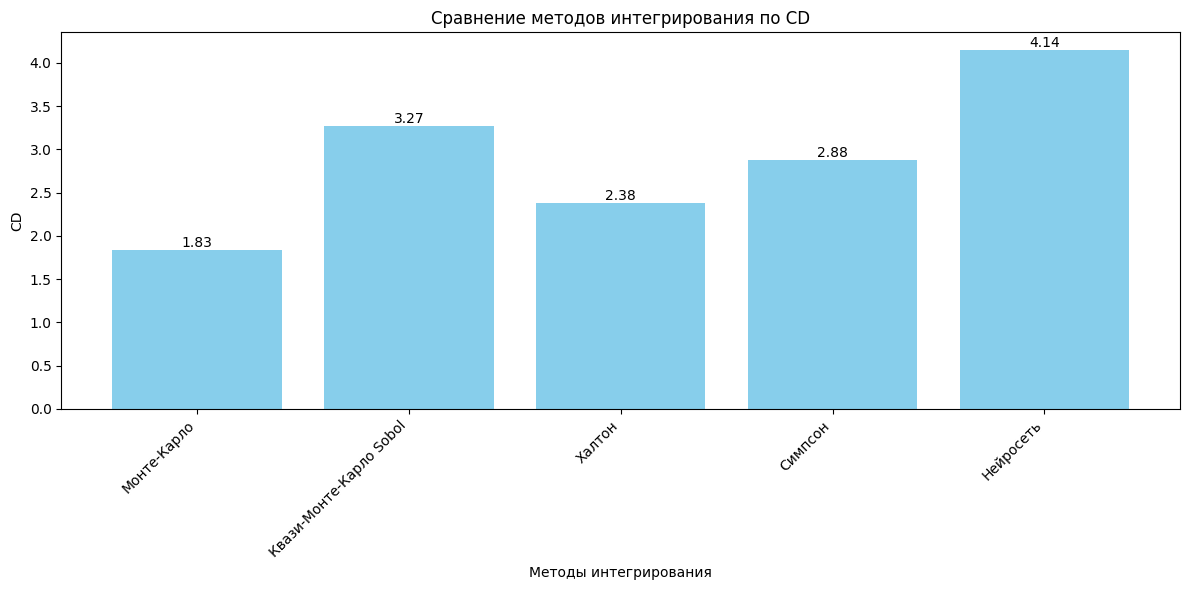

In [20]:
import numpy as np
import matplotlib.pyplot as plt

methods = [
    # "Гаусс-Лежандр",
    "Монте-Карло",
    "Квази-Монте-Карло Sobol",
    # "Латинский гиперкуб",
    "Халтон",
    "Симпсон",
    "Нейросеть"
]

cd_values = [
    # CD_I_gauss,
    CD_integral_monte_carlo,
    CD_integrate_with_quasi_monte_carlo,
    # CD_I_lhs,
    CD_I_halton,
    CD_I_simpson,
    CD_I_NNI
]

plt.figure(figsize=(12, 6))
bars = plt.bar(methods, cd_values, color='skyblue')
plt.xlabel("Методы интегрирования")
plt.ylabel("CD")
plt.title("Сравнение методов интегрирования по CD")
plt.xticks(rotation=45, ha="right")

# Добавляем значения CD над столбцами
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, round(yval, 2), ha='center', va='bottom')

plt.tight_layout()
plt.show()

# **Отрисовка графика зависимости CD от N (при фиксированных $р$ и n исследуемой ф-ии) всех методов интегрирования с помощью ф-ии integrate_with_nn**
зависит от выборки сформированной

In [23]:
from sklearn.preprocessing import MinMaxScaler
def integrate_with_nn(f, a, b, n, N):
    start_time = time.time()

    # Генерация данных
    X = generate_data(n, N, a, b, N_uniform, N_mg, N_border)
    y = f(X)

    # Масштабирование данных
    scalers = [MinMaxScaler(feature_range=(a[i], b[i])) for i in range(n)]
    X_scaled = np.zeros_like(X)
    for i in range(n):
        X_scaled[:, i] = scalers[i].fit_transform(X[:, i].reshape(-1, 1)).flatten()
    y_scaled = scalers[0].fit_transform(np.expand_dims(y, axis=1)).flatten()

    # Разделение данных на обучающую и валидационную выборки
    X_train, X_valid, y_train, y_valid = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=SEED)

    import random as python_random
    import tensorflow as tf
    from keras.layers import Dense, Input
    from keras.models import Model
    from keras.losses import MeanSquaredError
    import tf_levenberg_marquardt as lm
    from keras import backend as K


    class MeanSquaredErrorWithResiduals(MeanSquaredError):
        def residuals(self, y_true, y_pred):
            return y_true - y_pred

    loss_function = MeanSquaredErrorWithResiduals()


    def get_net(input_units, hidden_units, seed):
        python_random.seed(seed)
        tf.random.set_seed(seed)
        tf.keras.backend.set_floatx('float64')

        input_tensor = Input(shape=(input_units,))
        x = Dense(hidden_units, activation='sigmoid')(input_tensor)
        output_tensor = Dense(1, activation='linear')(x)
        model = Model(inputs=input_tensor, outputs=output_tensor)

        model_wrapper = lm.model.ModelWrapper(model)
        model_wrapper.compile(
            optimizer=tf.keras.optimizers.SGD(learning_rate=1.0),
            loss=loss_function,
            solve_method='qr',
            jacobian_max_num_rows=100,
            attempts_per_step=10
        )

        return model_wrapper

    def get_k(N, n, k1=4.33, k2=16):
        return int(pow(np.log10(N), -k1) * k2 * N / (n+2))

    k  = get_k(X_train.shape[0], n)
    model = get_net(n, k, SEED)

# bs = 0.0512
    start_time = time.time()

    history = model.fit(
        X_train,
        y_train,
    # batch_size=X_train.shape[0],
        batch_size=512,
    # batch_size=int(bs*X_train.shape[0]),
        epochs=100,
        validation_data=(X_valid, y_valid),
        verbose=1
    )

    from mpmath import polylog
    def Li(s, X):
        return np.array([float(polylog(s, x)) for x in X])

    def get_xsi(r, d, n):
        degree = int(r / pow(2, n-d))
        return pow(-1, degree)

    def get_Xsi(n, FD=False):
        r = 2**n
        Xsi = []
        for r in range(1, r+1):
            row = []
            for d in range(1, n+1):
                row.append(get_xsi(r, d, n))
            xsi = np.prod(row)
            Xsi.append(xsi)
        if FD:
            return -1*np.array(Xsi) # Fermi-Dirac version
        else:
            return np.array(Xsi)

    def get_l(r, i, n):
        num = int(r / pow(2, n-i))
        if num % 2 == 0:
            return 0
        else:
            return 1

    def get_L(n):
        r = 2**n
        L = []
        for r in range(1, r+1):
            row = []
            for i in range(1, n+1):
                row.append(get_l(r, i, n))
            L.append(row)
        return L

    def getNNI(W1, b1, W2, b2, a, b, n):
    # Вычисление размера области интегрирования
        ba_term = np.prod(b - a)
    # Создание массива из нижних и верхних пределов интегрирования
        ab = np.array([a, b])
        X = []
    # Получение матрицы L, определяющей, какие компоненты входных данных использовать в каждой точке сетки
        L = get_L(n)
        for l in L:
        # Инициализация переменной x значением смещения второго слоя нейронной сети
            x = - b1
        # Проход по каждой компоненте входных данных
            for i in range(n):
            # Вычитание взвешенной компоненты входных данных из x
                x -= W1[i] * ab[l[i], i]
            X.append(x)

    # Вычисление весов Xsi для каждой точки сетки
        Xsi = get_Xsi(n, False)
    # Вычисление значений Fi для каждой точки сетки
        Fi = np.array([xsi * Li(n, -np.exp(x, dtype=np.float128)) for xsi, x in zip(Xsi, X)])
        Fi = np.sum(Fi, axis=0)
        I = b2[0] * ba_term + np.sum(W2.flatten() * (ba_term + Fi / np.prod(W1, axis=0)))
        return I

    # Получение весов модели
    W1, b1, W2, b2 = model.get_weights()
    W1, b1, W2, b2 = W1.astype(np.float128), b1.astype(np.float128), W2.astype(np.float128), b2.astype(np.float128)

    # Вычисление интеграла
    I = getNNI(W1, b1, W2, b2, a, b, n)
    y_min, y_max = a[0], b[0]
    V_s = np.prod(X.max(axis=0) - X.min(axis=0))
    V_s_ = np.prod(b - a)
    I_NNI = V_s * (y.max() - y.min()) / (V_s_ * (y_max - y_min)) * I + (y.min() - (y.max() - y.min()) / (y_max - y_min) * y_min) * V_s

    end_time = time.time()
    NNI_time = end_time - start_time

    return I_NNI, NNI_time

/tmp/ipykernel_2622/2518857652.py:20: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  samples = qmc.scale(sampler.random(N), a, b)


Epoch 1/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 427ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0038 - val_loss: 0.0045
Epoch 2/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0038 - val_loss: 0.0044
Epoch 3/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0037 - val_loss: 0.0043
Epoch 4/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 257ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0037 - val_loss: 0.0043
Epoch 5/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 215ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0037 - val_loss: 0.0043
Epoch 6/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 218ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0037 - val_loss: 0.0042
Epoch 7/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 230ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0037 - val_loss: 0.0042
Epoch 8/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 230ms/step - attempts: 2.0000

/tmp/ipykernel_2622/2518857652.py:20: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  samples = qmc.scale(sampler.random(N), a, b)


Epoch 1/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 443ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0038 - val_loss: 0.0038
Epoch 2/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0038 - val_loss: 0.0037
Epoch 3/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 242ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0038 - val_loss: 0.0037
Epoch 4/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 250ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0037 - val_loss: 0.0037
Epoch 5/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 250ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0037 - val_loss: 0.0037
Epoch 6/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 227ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0037 - val_loss: 0.0036
Epoch 7/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 157ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0037 - val_loss: 0.0036
Epoch 8/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 157ms/step - attempts: 2.0000

/tmp/ipykernel_2622/2518857652.py:20: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  samples = qmc.scale(sampler.random(N), a, b)


Epoch 1/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 666ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0035 - val_loss: 0.0045
Epoch 2/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0035 - val_loss: 0.0044
Epoch 3/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0035 - val_loss: 0.0044
Epoch 4/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0034 - val_loss: 0.0044
Epoch 5/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0034 - val_loss: 0.0044
Epoch 6/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 148ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0034 - val_loss: 0.0043
Epoch 7/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step - attempts: 2.0000 - damping_factor: 1.0000e-04 - loss: 0.0034 - val_loss: 0.0043
Epoch 8/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 149ms/step - attempts: 2.0000

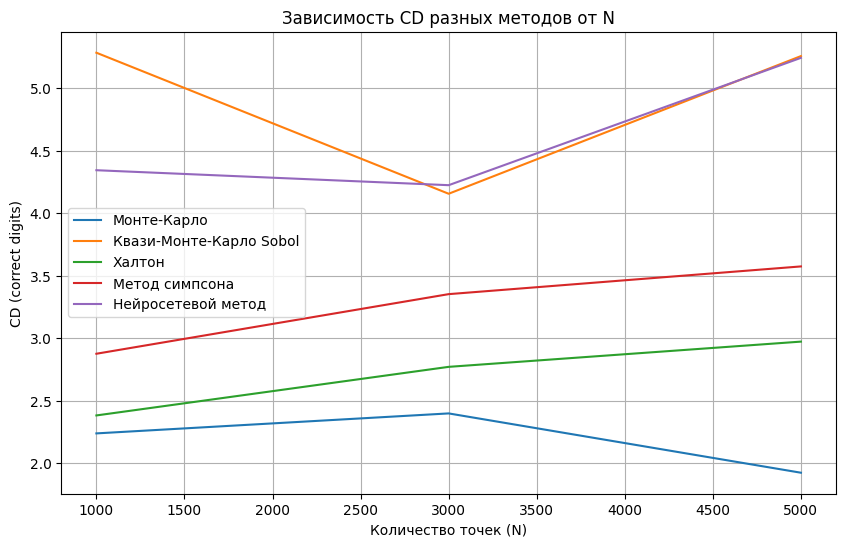

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# Функция для вычисления CD
def compute_cd(I_true, I_method):
    return -np.log10(np.abs((I_true - I_method) / I_true))

# Истинное значение интеграла
I_true = float(I_true)

# Диапазон значений N
N_values = range(1000, 7000, 2000)

# Списки для хранения CD
# CD_gauss = []
CD_monte_carlo = []
CD_quasi_monte_carlo = []
CD_cubature = []
CD_lhs = []
CD_halton = []
CD_simpson = []
# CD_trapezoidal = []
CD_nn = []

# Цикл по N
for N in N_values:
    # Вычисление интегралов для каждого метода
    # I_gauss, _ = integrate_with_gauss(f, a, b, n, m=5, nodes=nodes, weights=weights)
    I_monte_carlo, _ = integrate_with_monte_carlo(f, a, b, n, N)
    I_quasi_monte_carlo, _ = integrate_with_quasi_monte_carlo(f, a, b, n, N)
    # I_lhs, _ = latin_hypercube_sampling(f, a, b, n, N)
    I_halton, _ = integrate_with_halton(f, a, b, n, N)
    I_simpson, _ = integrate_with_simpson(f, a, b, n, N)
    I_nn, _ = integrate_with_nn(f, a, b, n, N)

    # Вычисление CD для каждого метода
    # CD_gauss.append(compute_cd(I_true, I_gauss))
    CD_monte_carlo.append(compute_cd(I_true, I_monte_carlo))
    CD_quasi_monte_carlo.append(compute_cd(I_true, I_quasi_monte_carlo))
    # CD_lhs.append(compute_cd(I_true, I_lhs))
    CD_halton.append(compute_cd(I_true, I_halton))
    CD_simpson.append(compute_cd(I_true, I_simpson))
    CD_nn.append(compute_cd(I_true, I_nn))

# Построение графика
plt.figure(figsize=(10, 6))
# plt.plot(N_values, CD_gauss, label="Гаусс-Лежандр")
plt.plot(N_values, CD_monte_carlo, label="Монте-Карло")
plt.plot(N_values, CD_quasi_monte_carlo, label="Квази-Монте-Карло Sobol")
# plt.plot(N_values, CD_lhs, label="Латинский гиперкуб")
plt.plot(N_values, CD_halton, label="Халтон")
plt.plot(N_values, CD_simpson, label="Метод симпсона")
plt.plot(N_values, CD_nn, label="Нейросетевой метод")

# Настройка графика
plt.xlabel("Количество точек (N)")
plt.ylabel("CD (correct digits)")
plt.title("Зависимость CD разных методов от N")
plt.legend()
plt.grid(True)
plt.show()

## **Визуализация распределния точек на функциях**

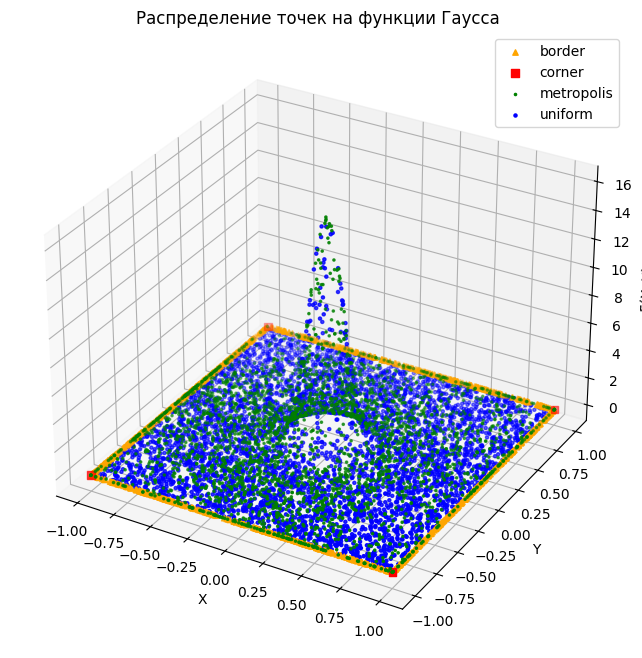

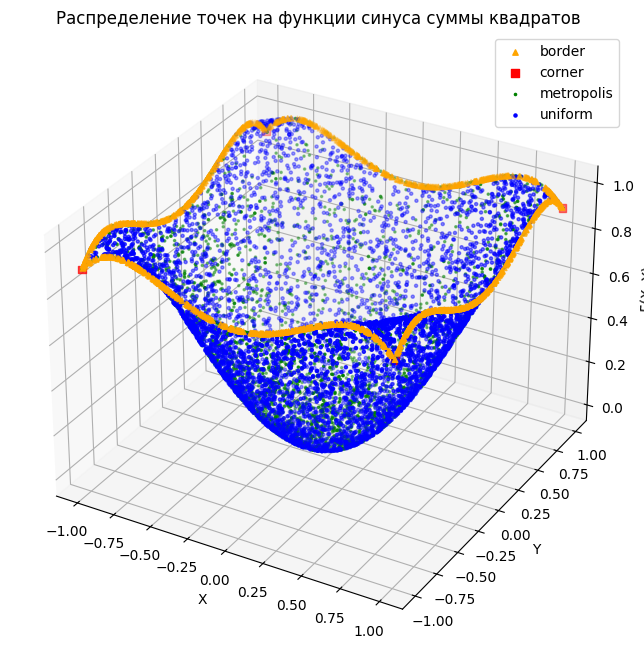

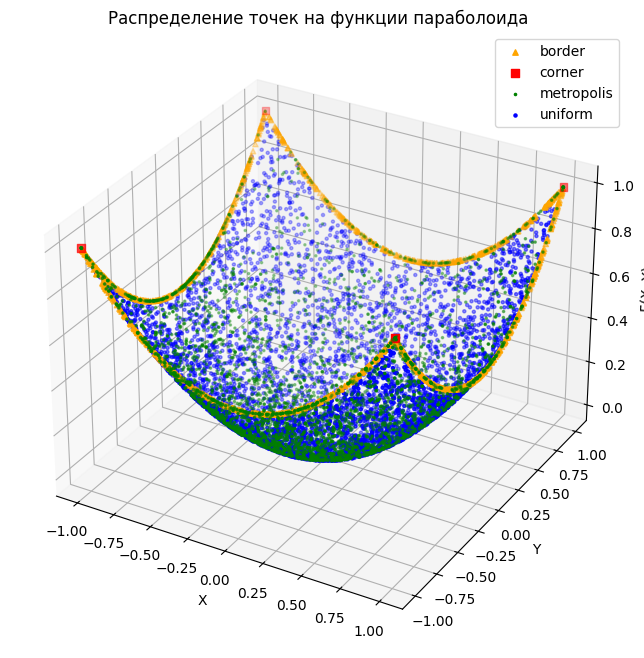

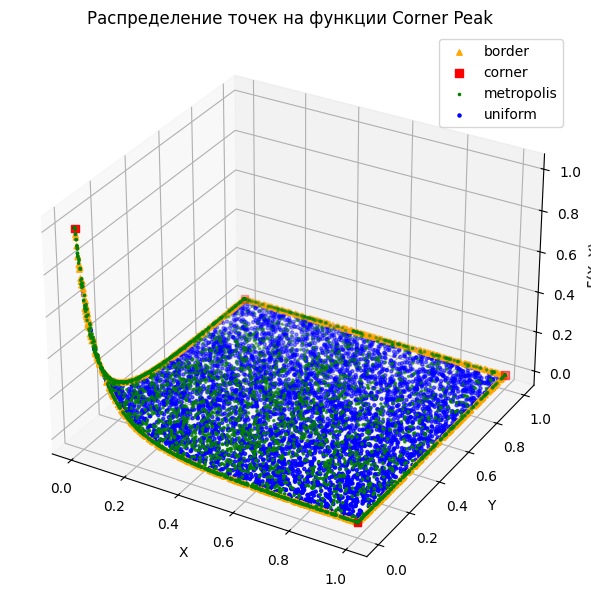

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Параметры генерации данных
n = 2
N = 10000
border_ratio = 0.12
ro = 0.4

def input_integration_limits(n):
    a = [-1, -1]
    b = [1, 1]
    return np.array(a), np.array(b)

a, b = input_integration_limits(n)

N_border_total = int(N * border_ratio)
N_mg = int(ro * (N - N_border_total))
N_uniform = (N - N_border_total) - N_mg

def generate_data_with_types(n, N, a, b, N_uniform, N_mg, N_border):
    # Равномерные точки
    X_uniform = np.random.uniform(a, b, size=(N_uniform, n))
    types_uniform = np.array(['uniform'] * N_uniform)

    # Функция Метрополиса-Гастингса
    def metropolis_hastings(n, N, a, b):
        X_mg = np.zeros((N, n))
        x_current = np.random.uniform(a, b, size=n)
        for i in range(N):
            x_proposed = x_current + np.random.normal(scale=0.2, size=n)
            x_proposed = np.clip(x_proposed, a, b)
            alpha = min(1, np.exp(-np.sum(x_proposed**2)) / np.exp(-np.sum(x_current**2)))
            if np.random.rand() < alpha:
                x_current = x_proposed
            X_mg[i] = x_current
        return X_mg

    X_mg = metropolis_hastings(n, N_mg, a, b)
    types_mg = np.array(['metropolis'] * N_mg)

    # Угловые точки
    corners = np.array(np.meshgrid(*[[a[i], b[i]] for i in range(n)])).T.reshape(-1, n)
    X_corners = corners
    types_corners = np.array(['corner'] * len(corners))
    n_corners = len(corners)

    # Граничные точки (не угловые)
    X_border_remaining_list = []
    n_remaining_border = max(0, N_border - n_corners)
    num_per_edge = max(0, n_remaining_border // (2 * n))
    for dim in range(n):
        for bound in [a[dim], b[dim]]:
            for _ in range(num_per_edge):
                point = np.random.uniform(a, b, size=n)
                point[dim] = bound
                X_border_remaining_list.append(point)
    X_border_remaining = np.array(X_border_remaining_list)
    types_border = np.array(['border'] * len(X_border_remaining))

    # Объединяем все точки и их типы
    X = np.vstack([X_uniform, X_mg, X_corners, X_border_remaining])
    types = np.hstack([types_uniform, types_mg, types_corners, types_border])

    # Перемешиваем (опционально, но полезно для порядка)
    permutation = np.random.permutation(X.shape[0])
    X = X[permutation]
    types = types[permutation]
    return X, types

# Генерируем данные с типами
X, types = generate_data_with_types(n, N, a, b, N_uniform, N_mg, N_border_total)

def input_integration_limits(n):
    a = [-1, -1]
    b = [1, 1]
    return np.array(a), np.array(b)

a, b = input_integration_limits(n)

# --- Функции ---
def gaussian_for_plot_points(X, center=None, sigma=None):
    n = X.shape[1]
    if center is None:
        center = np.array([(b[i] + a[i]) / 2 for i in range(n)])
    if sigma is None:
        sigma = np.ones(n) * 0.1 # Уменьшил sigma для лучшей видимости
    exponent = -0.5 * np.sum(((X - center) / sigma)**2, axis=1)
    return np.exp(exponent) / np.prod(sigma * np.sqrt(2 * np.pi))

def ellipse_for_plot_points(X):
    return np.sin(np.sum(X**2, axis=1))

def paraboloid_for_plot_points(X):
    return 0.5 * np.sum(X**2, axis=1)

def copeak_for_plot_points(X, u=None, a_val=None):
    d = X.shape[1]
    if u is None:
        u = np.full(d, 0.5)
    if a_val is None:
        a_val = np.full(d, 5)
    total_sum = np.dot(X, a_val)
    return (1 + total_sum) ** (-d - 1)

# --- Визуализация с выделением типов точек ---
functions_points = {
    "Гаусса": gaussian_for_plot_points,
    "синуса суммы квадратов": ellipse_for_plot_points,
    "параболоида": paraboloid_for_plot_points,
}

colors = {'uniform': 'blue', 'metropolis': 'green', 'corner': 'red', 'border': 'orange'}
markers = {'uniform': 'o', 'metropolis': '.', 'corner': 's', 'border': '^'}
sizes = {'uniform': 5, 'metropolis': 10, 'corner': 30, 'border': 15}
font = {'weight': 'bold', 'size': 14}
legend_font = {'weight': 'bold', 'size': 12}

for name, func in functions_points.items():
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    Z = func(X)
    for type_name in np.unique(types):
        subset_x = X[types == type_name]
        subset_z = Z[types == type_name]
        ax.scatter(subset_x[:, 0], subset_x[:, 1], subset_z, c=colors[type_name], marker=markers[type_name], s=sizes[type_name], label=type_name)

    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('F(X, Y)')
    ax.set_title(f'Распределение точек на функции {name}')
    ax.legend()
    plt.show()

# Визуализация Corner Peak отдельно с пределами от 0 до 1
fig_copeak = plt.figure(figsize=(10, 8))
ax_copeak = fig_copeak.add_subplot(111, projection='3d')

def input_integration_limits_copeak(n):
    a_copeak = [0, 0]
    b_copeak = [1, 1]
    return np.array(a_copeak), np.array(b_copeak)

a_copeak, b_copeak = input_integration_limits_copeak(n)
X_copeak, types_copeak = generate_data_with_types(n, N, a_copeak, b_copeak, N_uniform, N_mg, N_border_total)
Z_copeak = copeak_for_plot_points(X_copeak)
for type_name in np.unique(types_copeak):
    subset_x = X_copeak[types_copeak == type_name]
    subset_z = Z_copeak[types_copeak == type_name]
    ax_copeak.scatter(subset_x[:, 0], subset_x[:, 1], subset_z, c=colors[type_name], marker=markers[type_name], s=sizes[type_name], label=type_name)

ax_copeak.set_xlabel('X')
ax_copeak.set_ylabel('Y')
ax_copeak.set_zlabel('F(X, Y)')
ax_copeak.set_title('Распределение точек на функции Corner Peak')
ax_copeak.legend()

plt.subplots_adjust(left=0.15, right=0.85, bottom=0.15, top=0.85)
plt.show()

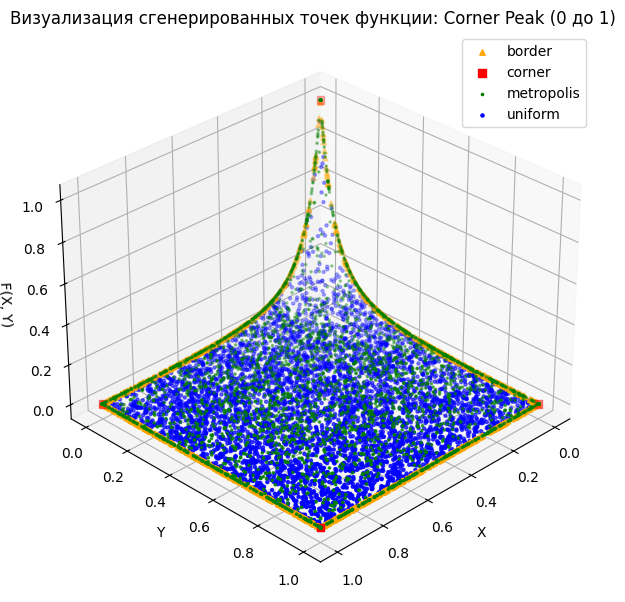

In [27]:
# Визуализация Corner Peak отдельно с пределами от 0 до 1
fig_copeak = plt.figure(figsize=(10, 8))
ax_copeak = fig_copeak.add_subplot(111, projection='3d')

def input_integration_limits_copeak(n):
    a_copeak = [0, 0]
    b_copeak = [1, 1]
    return np.array(a_copeak), np.array(b_copeak)

a_copeak, b_copeak = input_integration_limits_copeak(n)
X_copeak, types_copeak = generate_data_with_types(n, N, a_copeak, b_copeak, N_uniform, N_mg, N_border_total)
Z_copeak = copeak_for_plot_points(X_copeak)
for type_name in np.unique(types_copeak):
    subset_x = X_copeak[types_copeak == type_name]
    subset_z = Z_copeak[types_copeak == type_name]
    ax_copeak.scatter(subset_x[:, 0], subset_x[:, 1], subset_z, c=colors[type_name], marker=markers[type_name], s=sizes[type_name], label=type_name)

ax_copeak.set_xlabel('X')
ax_copeak.set_ylabel('Y')
ax_copeak.set_zlabel('F(X, Y)')
ax_copeak.set_title('Визуализация сгенерированных точек функции: Corner Peak (0 до 1)')
ax_copeak.legend()
ax_copeak.view_init(elev=30, azim=45)  # Изменение ракурса
plt.subplots_adjust(left=0.15, right=0.85, bottom=0.15, top=0.85)
plt.show()

In [28]:
# Простая визуализация всех точек
def visualize_sampling(X, func):
    y = func(X)

    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')

    ax.scatter(X[:, 0], X[:, 1], y, c='blue', s=5, label="Все точки")

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("f(X)")
    ax.set_title("Распределение всех точек на функции")
    ax.legend()
    plt.show()

X: это матрица (двумерный массив NumPy), которая содержит координаты сгенерированных случайных точек.

Размерность X: N x n, где N - количество точек, n - количество измерений (переменных интегрирования).  
Каждая строка X соответствует одной случайной точке.  
Каждый столбец X соответствует одной переменной интегрирования.

X - матрица, содержащая координаты этих точек.  
Количество точек в каждом измерении (точнее, ожидаемое количество) пропорционально размеру диапазона интегрирования для этой переменной.  
Мы не можем точно вычислить количество точек в каждом измерении из-за случайности генерации точек.

Метрика **$ CD $** представляет собой значение, основанное на относительной ошибке между вычисленным интегралом $ I_{NNI} $ и аналитическим значением $ I_{true} $.

Формула для $ CD $:
$$
CD = -\log_{10}\left(\frac{|I_{true} - I_{NNI}|}{|I_{true}|}\right)
$$

### Как интерпретировать $ CD $
- **Разница между значениями**: $ |I_{true} - I_{NNI}| $ представляет абсолютную ошибку между аналитическим решением и численным решением, то есть, насколько они отличаются.

- **Относительная ошибка**: деление абсолютной ошибки на $ |I_{true}| $ позволяет оценить ошибку в контексте величины интеграла. Если $ I_{true} $ больше, чем ошибка, результат будет меньше 1, что означает, что ошибка относительно небольшая.

- **Логарифмическое преобразование**: применение отрицательного логарифма к этому значению. Это приводит к тому, что:
  - Если $ I_{NNI} $ близок к $ I_{true} $, значение $ CD $ будет большим (и положительным).
  - Если $ I_{NNI} $ далеко от $ I_{true} $, значение $ CD $ будет меньшим (может стать отрицательным).


Вычисленное значение $ I_{NNI} = 639.741 $ и аналитическое значение $ I_{true} = 640 $.
Разница между ними составляет $ |640 - 639.741| = 0.259 $.

**Относительная ошибка**:
$$
\frac{0.259}{640} \approx 0.0004046875
$$

**Применяя логарифм**:
$$
CD = -\log_{10}(0.0004046875) \approx 3.3936280627441976312
$$

Чем выше значение $ CD $, тем меньше относительная ошибка и тем больше уверенность в том, что численное значение близко к аналитическому.
